# Chromatid shape model Figure

Creates the Figure of a single chromatid for the paper.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from mitosim.geometry.chromosome import chromosome_shape, place_chromatid
from mitosim.geometry.karyotype import ChromosomeSpec

OUT_DIR = Path("../results/chromatid_model_figure")

## Build one representative chromatid



In [ ]:
rng = np.random.default_rng(0)
spec = ChromosomeSpec(name="illustrative", length=4.0, radius=0.35, centromere_index=32.0)  # submetacentric-like, for a clearly asymmetric p/q bend
control, radius = chromosome_shape(rng, spec, bend_deg_range=(120.0, 120.0))  # Chromosome shape with 120 degree bend

N_SAMPLES = 200
chromatid = place_chromatid(
    control, radius, chromosome_id=0, sister=0,
    position=np.zeros(3), rotation=np.eye(3), lateral_offset=0.0, n_samples=N_SAMPLES,
)
centreline, tube_radii = chromatid.points, chromatid.radii
print(f"{len(control)} control points -> {N_SAMPLES} sampled centreline points")
print("control points (canonical local frame):")
for label, pt in zip(["telomere (p)", "mid-arm (p)", "centromere", "mid-arm (q)", "telomere (q)"], control):
    print(f"  {label:14s} {np.round(pt, 3)}")

5 control points -> 200 sampled centreline points
control points (canonical local frame):
  telomere (p)   [0.64  1.109 0.   ]
  mid-arm (p)    [0.31  0.708 0.025]
  centromere     [0. 0. 0.]
  mid-arm (q)    [ 0.641 -1.091  0.313]
  telomere (q)   [ 1.36  -2.356  0.   ]


## Rotation-minimizing frame + tube mesh


In [3]:
def rotation_minimizing_frames(points: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    n = len(points)
    tangents = np.zeros_like(points)
    tangents[:-1] = points[1:] - points[:-1]
    tangents[-1] = tangents[-2]
    tangents /= np.linalg.norm(tangents, axis=1, keepdims=True)

    arbitrary = np.array([0.0, 0.0, 1.0]) if abs(tangents[0, 2]) < 0.9 else np.array([1.0, 0.0, 0.0])
    normal0 = np.cross(tangents[0], arbitrary)
    normal0 /= np.linalg.norm(normal0)

    normals = np.zeros_like(points)
    normals[0] = normal0
    for i in range(n - 1):
        v1 = points[i + 1] - points[i]
        c1 = np.dot(v1, v1)
        if c1 < 1e-12:
            normals[i + 1] = normals[i]
            continue
        r_l = normals[i] - (2.0 / c1) * np.dot(v1, normals[i]) * v1
        t_l = tangents[i] - (2.0 / c1) * np.dot(v1, tangents[i]) * v1
        v2 = tangents[i + 1] - t_l
        c2 = np.dot(v2, v2)
        normals[i + 1] = r_l if c2 < 1e-12 else r_l - (2.0 / c2) * np.dot(v2, r_l) * v2
    binormals = np.cross(tangents, normals)
    return tangents, normals, binormals


def tube_mesh(centreline: np.ndarray, radii: np.ndarray, n_theta: int = 160, n_cap: int = 24):
    tangents, normals, binormals = rotation_minimizing_frames(centreline)

    theta = np.linspace(0, 2 * np.pi, n_theta, endpoint=False)

    ring_dirs = np.cos(theta)[None, :, None] * normals[:, None, :] + np.sin(theta)[None, :, None] * binormals[:, None, :]
    surface = centreline[:, None, :] + radii[:, None, None] * ring_dirs
    surface = np.concatenate([surface, surface[:, :1, :]], axis=1)  # close the loop with an exact duplicate

    def hemisphere_cap(center, radius, tangent, normal, binormal, outward_sign):
        s = np.linspace(0, np.pi / 2, n_cap + 1)[1:]
        cap_r = radius * np.cos(s)
        cap_h = radius * np.sin(s) * outward_sign
        rings = (
            center[None, None, :]
            + cap_h[:, None, None] * tangent[None, None, :]
            + cap_r[:, None, None] * (np.cos(theta)[None, :, None] * normal[None, None, :]
                                       + np.sin(theta)[None, :, None] * binormal[None, None, :])[0]
        )
        return np.concatenate([rings, rings[:, :1, :]], axis=1)

    cap_start = hemisphere_cap(centreline[0], radii[0], tangents[0], normals[0], binormals[0], -1.0)[::-1]
    cap_end = hemisphere_cap(centreline[-1], radii[-1], tangents[-1], normals[-1], binormals[-1], 1.0)
    surface = np.concatenate([cap_start, surface, cap_end], axis=0)
    return surface[..., 0], surface[..., 1], surface[..., 2]


X, Y, Z = tube_mesh(centreline, tube_radii)

## Render

Tube surface (chromatin-like tone) with the true centreline traced through
its medial axis, and the 5 control points marked + labelled -- the two
things the tube is actually built from.

wrote ../results/chromatid_model_figure/chromatid_model_figure.pdf and .png


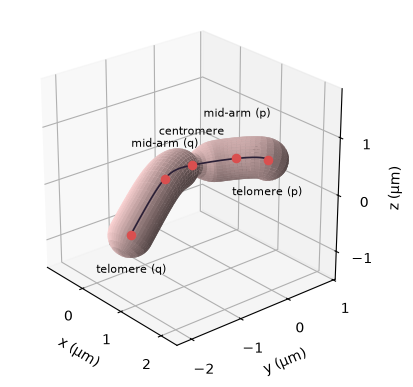

In [ ]:
fig = plt.figure(figsize=(5, 4))
ax = fig.add_subplot(111, projection="3d")
ax.computed_zorder = False


ax.plot_surface(X, Y, Z, color="#ffd5d5ff", alpha=1.0, linewidth=0, antialiased=True, shade=True, zorder=1)

ax.plot(centreline[:, 0], centreline[:, 1], centreline[:, 2], color="#2a1f36", linewidth=1.2, zorder=10)

labels = ["telomere (p)", "mid-arm (p)", "centromere", "mid-arm (q)", "telomere (q)"]
ax.scatter(control[:, 0], control[:, 1], control[:, 2], color="#d94f4f", s=35, zorder=20, depthshade=False)
offs=[-0.8,0.6,0.4,0.4,-0.8]
for label, pt,o in zip(labels, control,offs):
    ax.text(pt[0], pt[1], pt[2] + 0.15 + o, label, fontsize=8, ha="center", zorder=20)

all_pts = np.concatenate([X.ravel()[:, None], Y.ravel()[:, None], Z.ravel()[:, None]], axis=1)
mins, maxs = all_pts.min(axis=0), all_pts.max(axis=0)
centers = (mins + maxs) / 2
half_range = (maxs - mins).max() / 2 + 0.3
half_range*=0.7
ax.set_xlim(centers[0] - half_range, centers[0] + half_range)
ax.set_ylim(centers[1] - half_range, centers[1] + half_range)
ax.set_zlim(centers[2] - half_range, centers[2] + half_range)
ax.set_box_aspect((1, 1, 1))
ax.set_xticks([0,1,2])
ax.set_yticks([-2,-1,0,1])
ax.set_zticks([-1,0,1])


ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)"); ax.set_zlabel("z (µm)")
ax.view_init(elev=25, azim=-40)
plt.tight_layout()

OUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / "chromatid_model_figure.pdf", bbox_inches="tight")
fig.savefig(OUT_DIR / "chromatid_model_figure.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_DIR / 'chromatid_model_figure.pdf'} and .png")
plt.show()